In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

import openTSNE
import pandas as pd
import numpy as np
import pickle


import torch
from sklearn.decomposition import PCA
from datasets import load_dataset, load_from_disk

In [2]:
# Load encodings

blosum_dataset = load_from_disk("../data/encodings/blosum62/")
blosum_labels = blosum_dataset["elution_cleavage"]
blosum_labels = np.where(blosum_labels == 1,"cleavage site","non-cleavage site")

## Physicochemical 
physico_dataset = load_from_disk("../data/encodings/physic/")
physico_labels = physico_dataset["elution_cleavage"]
physico_labels = np.where(physico_labels == 1,"cleavage site","non-cleavage site")


In [8]:
print(physico_dataset["encoded_sequences"][0])

[[ 3.03  1.28  2.94  0.    0.    3.21  1.89  1.31  3.67  1.56]
 [ 0.11  0.05  0.29  0.    0.    0.41  0.22  0.06  0.14  0.15]
 [ 2.6   1.    5.89  0.    0.    8.08  4.77  1.6   3.    3.78]
 [ 0.26  0.31  1.79  0.    0.    2.25 -0.99 -0.04  1.22 -0.64]
 [ 5.6   6.11  5.67  6.07  6.07  5.94  9.99  5.7   6.02  3.09]
 [ 0.21  0.42  0.3   0.13  0.13  0.32  0.32  0.2   0.27  0.42]
 [ 0.36  0.23  0.38  0.15  0.15  0.42  0.27  0.28  0.49  0.21]]


In [2]:
# labels = pd.read_csv("data/c_test_downs.csv",usecols=['elution_cleavage'])['elution_cleavage'].values
# labels = np.where(labels == 1,"cleavage site","non-cleavage site")

In [2]:
# ESM2 embedding
esm2_embeddings = torch.load('data/embeddings/esm2_emb_50540seqs.pt')


In [3]:
esm2_embeddings.shape

torch.Size([50540, 12, 1280])

## Multiscale t-SNE
#### ESM2_avg,ESM2_concat, blosum62 conc

In [4]:
### ESM2 embedding concat

# Generate per-sequence representations via concatenating
esm2_embeddings_con = esm2_embeddings[:,1:-1,:].flatten(1).numpy()

aff_mult_esm2 = openTSNE.affinity.Multiscale(
    esm2_embeddings_con,
    perplexities=[50, 500],
    metric="cosine",
    n_jobs=12,
    random_state=42,
    verbose=True
)

initEsm2 = openTSNE.initialization.pca(esm2_embeddings_con, random_state=42)

esm2_emb_multi = openTSNE.TSNE(n_jobs=12).fit(
    affinities=aff_mult_esm2,
    initialization=initEsm2,
)

===> Finding 1500 nearest neighbors using Annoy approximate search using cosine distance...
   --> Time elapsed: 1301.30 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 12.13 seconds


In [5]:
### ESM2 embedding avg

# Generate per-sequence representations via averaging
# NOTE: token 0 is always a beginning-of-sequence token, so the first residue is token 1. Token 2 is eos

esm2_embeddings_avg =  esm2_embeddings[:,1:-1,:].mean(1).numpy()

aff_mult_esm2_avg = openTSNE.affinity.Multiscale(
    esm2_embeddings_avg,
    perplexities=[50, 500],
    metric="cosine",
    n_jobs=12,
    random_state=42,
    verbose=True
)

initEsm2_avg = openTSNE.initialization.pca(esm2_embeddings_avg, random_state=42)

esm2_emb_multi_avg = openTSNE.TSNE(n_jobs=12).fit(
    affinities=aff_mult_esm2_avg,
    initialization=initEsm2_avg,
)


===> Finding 1500 nearest neighbors using Annoy approximate search using cosine distance...
   --> Time elapsed: 107.76 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 12.01 seconds


In [6]:
### blosum62 encoding concat

blosum_encode = blosum_dataset["encoded_sequences"].flatten(1) # global representation concatenate


aff_multi_blosum62 = openTSNE.affinity.Multiscale(
    blosum_encode,
    perplexities=[50, 500],
    metric="cosine",
    n_jobs=12,
    random_state=42,
    verbose=True
)

initBlosum62 = openTSNE.initialization.pca(blosum_encode, random_state=42)

blosum62_emb_multi = openTSNE.TSNE(n_jobs=12).fit(
    affinities=aff_multi_blosum62,
    initialization=initBlosum62,
)

===> Finding 1500 nearest neighbors using Annoy approximate search using cosine distance...
   --> Time elapsed: 48.53 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 10.17 seconds


In [15]:
### blosum62 encoding avg

blosum_encode = blosum_dataset["encoded_sequences"].mean(2) # global representation avg


aff_multi_blosum62 = openTSNE.affinity.Multiscale(
    blosum_encode,
    perplexities=[50, 500],
    metric="cosine",
    n_jobs=12,
    random_state=42,
    verbose=True
)

initBlosum62 = openTSNE.initialization.pca(blosum_encode, random_state=42)

blosum62_emb_multi_avg = openTSNE.TSNE(n_jobs=12).fit(
    affinities=aff_multi_blosum62,
    initialization=initBlosum62,
)

===> Finding 1500 nearest neighbors using Annoy approximate search using cosine distance...
   --> Time elapsed: 30.74 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 10.70 seconds


In [20]:
### Physicochemical encoding concat

physico_encode = physico_dataset["encoded_sequences"].flatten(1) # global representation concatenate


aff_multi_physico = openTSNE.affinity.Multiscale(
    physico_encode,
    perplexities=[50, 500],
    metric="cosine",
    n_jobs=12,
    random_state=42,
    verbose=True
)

initphysico = openTSNE.initialization.pca(physico_encode, random_state=42)

physico_emb_multi = openTSNE.TSNE(n_jobs=12).fit(
    affinities=aff_multi_physico,
    initialization=initphysico,
)

===> Finding 1500 nearest neighbors using Annoy approximate search using cosine distance...
   --> Time elapsed: 34.43 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 11.10 seconds


In [28]:
### Physicochemical encoding avg

physico_encode = physico_dataset["encoded_sequences"].mean(2) # global representation average


aff_multi_physico = openTSNE.affinity.Multiscale(
    physico_encode,
    perplexities=[50, 500],
    metric="cosine",
    n_jobs=12,
    random_state=42,
    verbose=True
)

initphysico = openTSNE.initialization.pca(physico_encode, random_state=42)

physico_emb_multi_avg = openTSNE.TSNE(n_jobs=12).fit(
    affinities=aff_multi_physico,
    initialization=initphysico,
)

===> Finding 1500 nearest neighbors using Annoy approximate search using cosine distance...
   --> Time elapsed: 35.09 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 10.93 seconds


In [27]:
physico_dataset["encoded_sequences"].mean(2).shape

torch.Size([50540, 7])

In [7]:
def tsne_plot(data, labels, title="T-SNE Visualization of Sequence Embeddings",desc=None):
    # Create a DataFrame for plotting
    df_plot = pd.DataFrame({
        "x": data[:, 0],
        "y": data[:, 1],
        "sequence": labels  
    })
    
    # Create the T-SNE plot using Seaborn
    plt.figure(figsize=(10, 8))
    plt.axis('off')
    g = sns.scatterplot(data=df_plot, x="x", y="y", hue="sequence", palette=["blue", "orange"],alpha=0.3,s=15)  # Customize colors
    g.get_legend().set_title("")
    #g.legend(prop={'size': 20})
    plt.suptitle(title,fontsize=14,fontweight="bold",x=0.126,y=0.96,ha="left")
    plt.title(desc,fontsize=12,pad=10,loc="left")
    #plt.show()

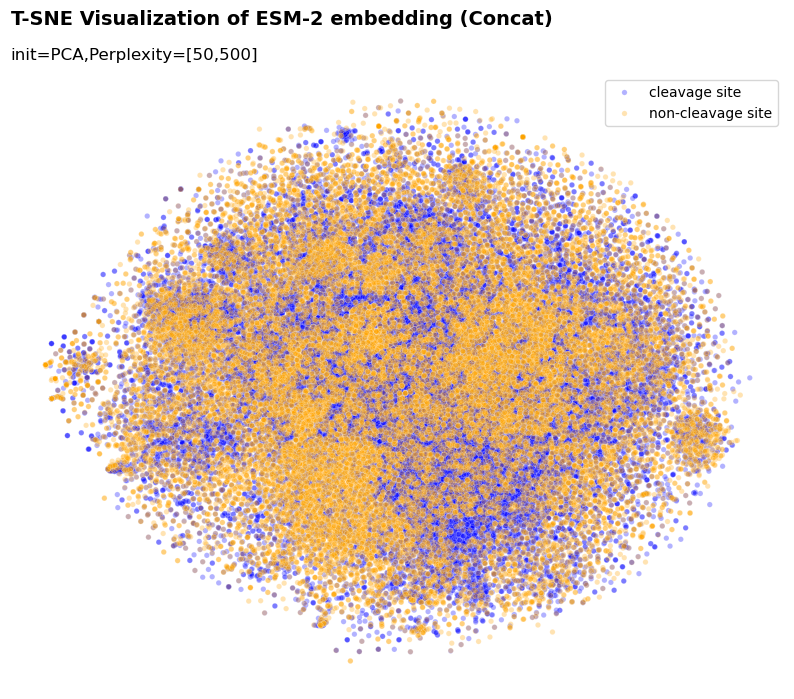

In [6]:
tsne_plot(esm2_emb_multi,labels,title="T-SNE Visualization of ESM-2 embedding (Concat)",desc="init=PCA,Perplexity=[50,500]")
plt.savefig(f'esm2concat_tsne_multi.png',format='png',bbox_inches='tight',dpi=300)

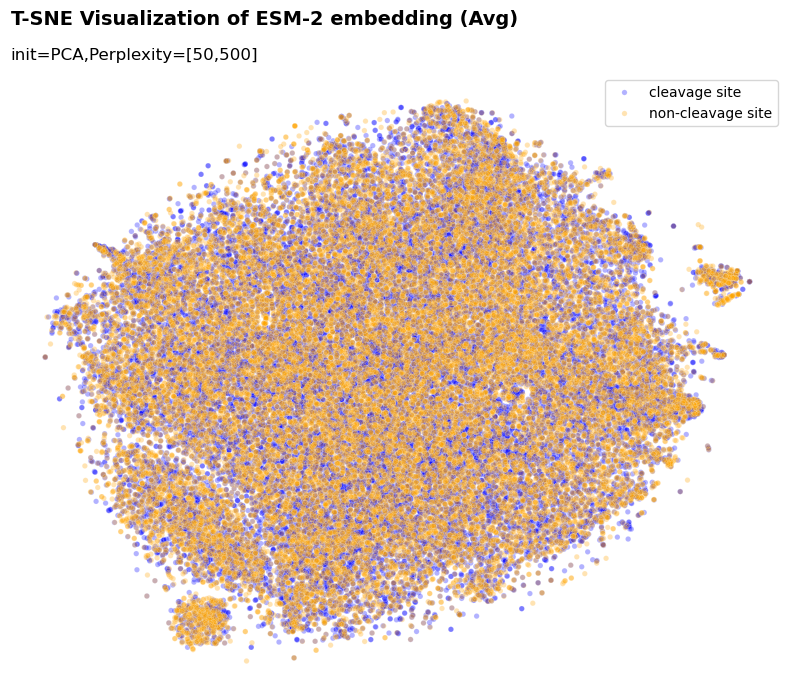

In [11]:
tsne_plot(esm2_emb_multi_avg,labels,title="T-SNE Visualization of ESM-2 embedding (Avg)",desc="init=PCA,Perplexity=[50,500]")
plt.savefig(f'esm2avg_tsne_multi.png',format='png',bbox_inches='tight',dpi=300)

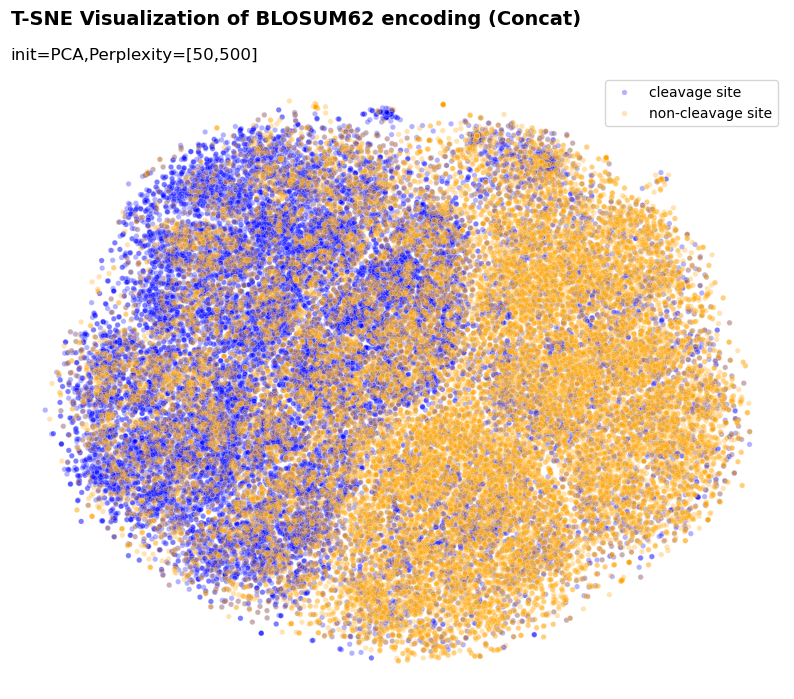

In [17]:
tsne_plot(blosum62_emb_multi,blosum_labels,title="T-SNE Visualization of BLOSUM62 encoding (Concat)",desc="init=PCA,Perplexity=[50,500]")
plt.savefig(f'blosum62concat_tsne_multi.png',format='png',bbox_inches='tight',dpi=300)

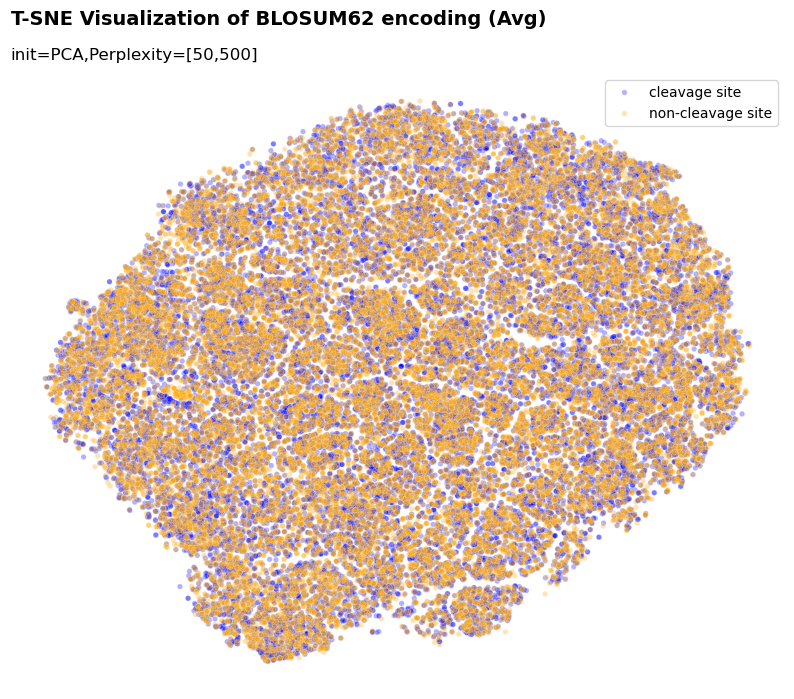

In [18]:
tsne_plot(blosum62_emb_multi_avg,blosum_labels,title="T-SNE Visualization of BLOSUM62 encoding (Avg)",desc="init=PCA,Perplexity=[50,500]")
plt.savefig(f'blosum62avg_tsne_multi.png',format='png',bbox_inches='tight',dpi=300)

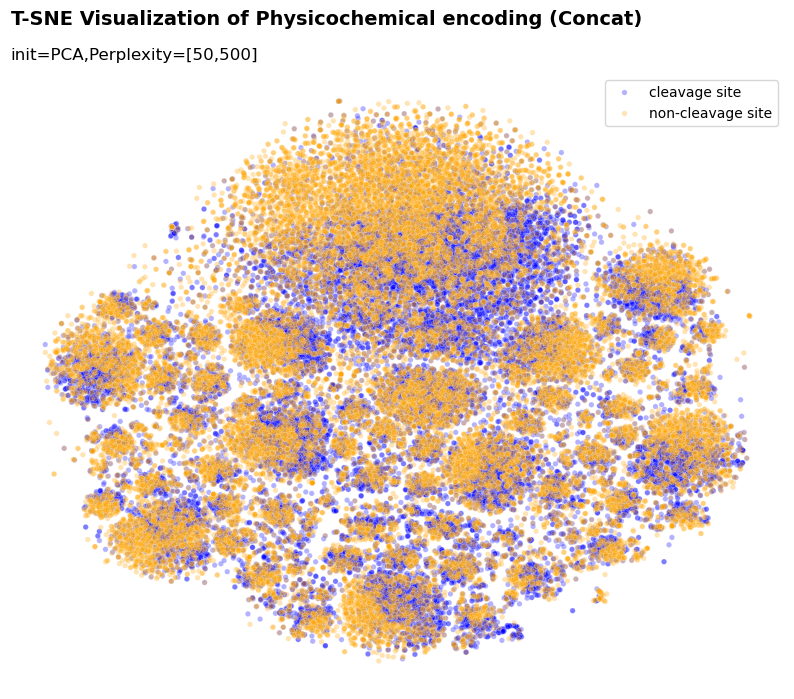

In [25]:
tsne_plot(physico_emb_multi,physico_labels,title="T-SNE Visualization of Physicochemical encoding (Concat)",desc="init=PCA,Perplexity=[50,500]")
plt.savefig(f'Physicoconcat_tsne_multi.png',format='png',bbox_inches='tight',dpi=300)

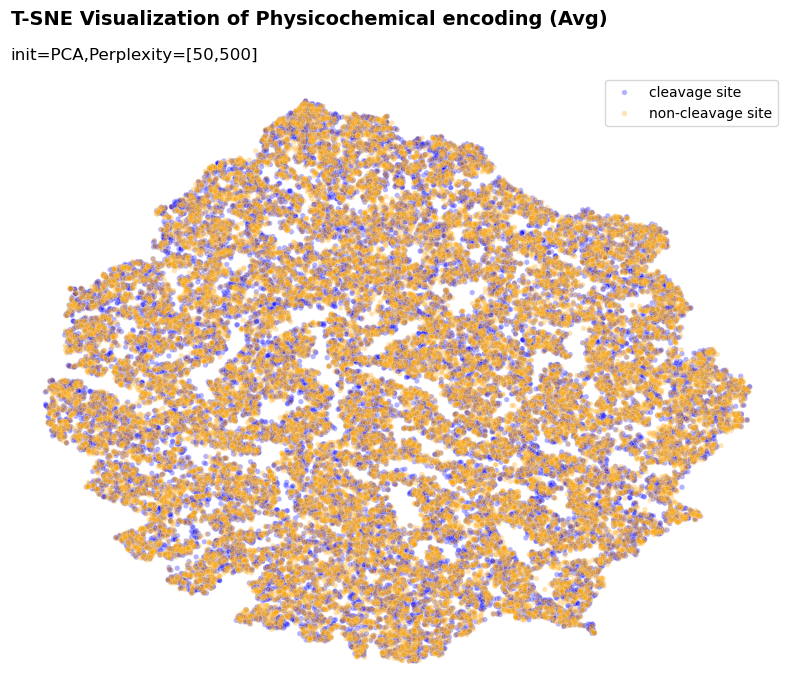

In [29]:
tsne_plot(physico_emb_multi_avg,physico_labels,title="T-SNE Visualization of Physicochemical encoding (Avg)",desc="init=PCA,Perplexity=[50,500]")
plt.savefig(f'PhysicoAvg_tsne_multi.png',format='png',bbox_inches='tight',dpi=300)